# STATE — GO_BP cross-ontology check

Gene Ontology Biological Process groups genes by the processes they contribute to, such as cell division or DNA repair. The audit used these groups to calculate training support and checked whether the pathway-support association also appeared with this annotation system.

Run the six sections in order. Every custom calculation is written in these cells; no external analysis scripts or saved derived tables are required. The analysis uses official STATE released evaluation scores for the HVG and SE representations. The audit does not fine-tune STATE or run fresh inference.

Use Python 3.11 with `numpy==1.26.4 pandas==2.2.2 scipy==1.13.1 matplotlib==3.9.4 pyarrow==16.1.0 rdkit==2025.3.6 ipython ipykernel`. An existing raw-data cache can be selected with `STATE_PRIMARY_INPUTS`; each input is checked against its declared SHA256 before reuse.


## 1. Data source/acquisition

The source table specifies pinned score downloads, split definitions, and annotation inputs. Annotation files are distributed in a versioned public data package; their upstream providers are listed alongside the package URL. Only raw annotations are read from that package.


In [1]:
ANALYSIS_ID="state-featured/test-15"
TITLE='GO_BP cross-ontology check'

from pathlib import Path
import ast, csv, gzip, hashlib, io, json, math, os, re, shutil, tarfile, time, tomllib, urllib.request
from collections import Counter, defaultdict
from concurrent.futures import ThreadPoolExecutor
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
STARTED=time.time()
INPUTS=Path(os.environ.get('STATE_PRIMARY_INPUTS','state_primary_inputs')).resolve()
OUTPUTS=Path('state_primary_outputs')/ANALYSIS_ID.split('/')[-1]
INPUTS.mkdir(parents=True,exist_ok=True)
OUTPUTS.mkdir(parents=True,exist_ok=True)
pd.set_option('display.max_colwidth',100)
pd.set_option('display.max_rows',100)


In [2]:
SOURCES=[{'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 360951,
  'sha256': '42dd8ef412843c9e0782c72d669ef352d40af63fbe7f1d11ab26b9d0f188a5e3'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 423657,
  'sha256': 'fff2d8598e61229052483d2215809b267a9be5b28187147ea8eaa078a115280d'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 368088,
  'sha256': 'c518efe5a6492b62dd3aea985e6f50ca5a8b2e9df742134041e313d2e6605ba6'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 406063,
  'sha256': '397533d40a2efba9d75a54fca855fc39db1562ff50c765408e9afdea61826803'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 506756,
  'sha256': '0c930ad038b56c6f43d25896a15cd68e121d8902e5457718b4dfc9f163f10604'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 582103,
  'sha256': '3efc817549bbf24edd6e427fb99466f58de8fadb3a4b4335523f5cfac1bc8098'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 538095,
  'sha256': '8bd145c4667e03c9e367079dcfb38126e4e1f06b562f8a3fa6d1eaa1d0ba5821'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-HVG-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'bb6a9562cbbf1fd152df14cc53b4cc7517c77175',
  'path': 'scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c77175/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 575323,
  'sha256': 'c187b3a026c8381a84acbe5035efa30947a6774c82a6519749b1b37e85fdd14d'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 354986,
  'sha256': '1e4cd7df90212c61f7f171fcd5da69449e5e3edde4462201b8dedd99d07aa2c4'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 403167,
  'sha256': '7352c785869bf83402fb5dc79ebdbb2d911d77153c3530db4b9f143a5bec2626'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 365675,
  'sha256': 'bcba9ae671c391e78b11efda0bb0d3d48f8052541ae7599d522b293e96e3594c'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 411935,
  'sha256': '36b6afce7889485a2afa99a13449b59dbd06d14d564e985a37629f93101ffd34'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv',
  'bytes': 509894,
  'sha256': '9b7b329faa11cfdfbbac37ad571bdf47e8af7f988d61561eab51d80dce9d643a'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv',
  'bytes': 568100,
  'sha256': '372db67f297565e5542cac1bda688586c07e03e92a999bea953a9df812ba5317'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/k562/eval_best.ckpt/k562_results.csv',
  'bytes': 528013,
  'sha256': 'eaf22cc6169fa98ab90913366529db232ac2109fe421599f66d47b14ffd183b3'},
 {'kind': 'released_score',
  'repo': 'arcinstitute/ST-SE-Replogle',
  'filename': 'zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'revision': 'e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c',
  'path': 'scores/ST-SE-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'url': 'https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d69c/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv',
  'bytes': 535692,
  'sha256': 'ce7034b9e7af7255f44347ac9fdcbdd41e13b8ce674cab3c2700c0b41a1b1ffa'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/hepg2.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/hepg2.toml',
  'bytes': 9122,
  'sha256': '7f8d5df29942f7532fef09b23a0a8deec7b8339bfe7817505b977bd894813962'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/jurkat.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/jurkat.toml',
  'bytes': 10393,
  'sha256': '9606316c24dfd140bbfe7e252375c18283d4f4f10b5a4adcb463a87cd1472634'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/k562.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/k562.toml',
  'bytes': 9333,
  'sha256': 'a794ae85cacbb8ae2ce59ad5ba0fb465f5be244950b84aea28c7fa29226597c3'},
 {'kind': 'split',
  'path': 'splits/replogle_tomls/rpe1.toml',
  'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/original/state_generalizability_20260602_single_controller/external/state/state_preprint_toml_files/replogle_tomls/rpe1.toml',
  'bytes': 10158,
  'sha256': '1681633c6b902933a8e83aae07d941ba2e63e5b968be0b80fea61a247308ecdc'}]
ANNOTATIONS=[{'path': 'annotations/Ensembl2Reactome_Homo_sapiens.txt',
  'member': 'original/state_generalizability_continued_20260603/external/Ensembl2Reactome_Homo_sapiens.txt',
  'bytes': 145040178,
  'sha256': '7bd9f04802324d18fe50431d3e8bb9fce56f64aaf0afba83b7078e9d8623e0c5',
  'source_url': 'https://reactome.org/download/current/Ensembl2Reactome_All_Levels.txt'},
 {'path': 'annotations/go-basic.obo',
  'member': 'original/state_generalizability_continued_20260603/external/go-basic.obo',
  'bytes': 32212518,
  'sha256': '923645000afcb1df0e72e252b64950b1c2bcc98c9393fec8c1dd1a0f7c9d4d77',
  'source_url': 'https://current.geneontology.org/ontology/go-basic.obo'},
 {'path': 'annotations/goa_human.gaf.gz',
  'member': 'original/state_generalizability_continued_20260603/external/goa_human.gaf.gz',
  'bytes': 15041996,
  'sha256': 'db472faff1785878521693af62646546cea6af4a386609dd01c72c0554a46a30',
  'source_url': 'https://current.geneontology.org/annotations/goa_human.gaf.gz'},
 {'path': 'annotations/hgnc_complete_set.txt',
  'member': 'original/state_generalizability_continued_20260603/external/hgnc_complete_set.txt',
  'bytes': 16738373,
  'sha256': '1f8826fb0b519296233dba3f987bc38efcfb3706032ed0c0685a6936f9b11e93',
  'source_url': 'https://storage.googleapis.com/public-download-files/hgnc/tsv/tsv/hgnc_complete_set.txt'}]
ANNOTATION_PACKAGE={'path': 'annotations.tar.gz', 'url': 'https://raw.githubusercontent.com/shreyjain11/SPECTRAagent/a3b7272548095e7f3df2dabe048c953d0b6316dd/reproduction/primary/state/payloads/state-historical-annotations.tar.gz', 'bytes': 40411527, 'sha256': 'ddba844c5803aeb2e32c51f72889b16fc77efa13f1ace9ba541508f4ed31c059'}


In [3]:
def sha256_file(path):
    h=hashlib.sha256()
    with Path(path).open('rb') as f:
        for block in iter(lambda:f.read(8<<20),b''):h.update(block)
    return h.hexdigest()

def verified(path,entry):
    return path.is_file() and path.stat().st_size==entry['bytes'] and sha256_file(path)==entry['sha256']

def download(entry):
    path=INPUTS/entry['path']
    if verified(path,entry):return path
    path.parent.mkdir(parents=True,exist_ok=True)
    temporary=path.with_name(path.name+'.part')
    for attempt in range(4):
        try:
            request=urllib.request.Request(entry['url'],headers={'User-Agent':'SPECTRA-notebook/1.0'})
            with urllib.request.urlopen(request,timeout=120) as response, temporary.open('wb') as f:
                shutil.copyfileobj(response,f,8<<20)
            if not verified(temporary,entry):raise ValueError('Download checksum mismatch: '+entry['path'])
            temporary.replace(path)
            return path
        except Exception:
            if attempt==3:raise
            time.sleep(2**attempt)

with ThreadPoolExecutor(max_workers=4) as pool:
    downloaded=list(pool.map(download,SOURCES))
if ANNOTATIONS:
    missing=[s for s in ANNOTATIONS if not verified(INPUTS/s['path'],s)]
    if missing:
        archive_path=download(ANNOTATION_PACKAGE)
        with tarfile.open(archive_path) as archive:
            for entry in missing:
                path=INPUTS/entry['path'];path.parent.mkdir(parents=True,exist_ok=True)
                with archive.extractfile(entry['member']) as source,path.open('wb') as destination:
                    shutil.copyfileobj(source,destination)
                assert verified(path,entry),entry['path']
    assert all(verified(INPUTS/s['path'],s) for s in ANNOTATIONS)
source_receipts=[{'path':s['path'],'url':s['url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in SOURCES]
source_receipts += [{'path':s['path'],'url':ANNOTATION_PACKAGE['url'],'source_url':s['source_url'],'bytes':s['bytes'],'sha256':s['sha256']} for s in ANNOTATIONS]
display(pd.DataFrame(source_receipts)[['path','bytes','url']])
print('Verified source files:',len(source_receipts))


,path,bytes,url
0,scores/ST-HVG-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,360951,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
1,scores/ST-HVG-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv,423657,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
2,scores/ST-HVG-Replogle/fewshot/k562/eval_best.ckpt/k562_results.csv,368088,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
3,scores/ST-HVG-Replogle/fewshot/rpe1/eval_best.ckpt/rpe1_results.csv,406063,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
4,scores/ST-HVG-Replogle/zeroshot/hepg2/eval_best.ckpt/hepg2_results.csv,506756,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
5,scores/ST-HVG-Replogle/zeroshot/jurkat/eval_best.ckpt/jurkat_results.csv,582103,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
6,scores/ST-HVG-Replogle/zeroshot/k562/eval_best.ckpt/k562_results.csv,538095,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
7,scores/ST-HVG-Replogle/zeroshot/rpe1/eval_best.ckpt/rpe1_results.csv,575323,https://huggingface.co/arcinstitute/ST-HVG-Replogle/resolve/bb6a9562cbbf1fd152df14cc53b4cc7517c7...
8,scores/ST-SE-Replogle/fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,354986,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...
9,scores/ST-SE-Replogle/fewshot/jurkat/eval_best.ckpt/jurkat_results.csv,403167,https://huggingface.co/arcinstitute/ST-SE-Replogle/resolve/e324967ff4cea5ec199e29bcbb5c1f00e5b9d...


Verified source files: 24


## 2. Data processing

Parse the released condition identifiers and source filenames, retain the context/protocol/representation labels, and read the prospective annotation or chemical features. Metric values remain the official released scores.


In [4]:
def i_norm_name(x: str) -> str:
    x = str(x).strip().lower()
    x = re.sub('\\s+', ' ', x)
    return x

def i_loose_name(x: str) -> str:
    x = i_norm_name(x)
    x = re.sub('\\([^)]*\\)', '', x)
    x = re.sub('\\b(hydrochloride|hydrate|monohydrate|dihydrate|trihydrate|mesylate|maleate|tosylate|sodium|calcium|potassium|phosphate|sulfate|citrate|acetate|hemihydrate|salt|solvate|tf)\\b', '', x)
    x = re.sub('[^a-z0-9]+', '', x)
    return x

def i_parse_perturbation(value: str):
    """Parse STATE perturbation strings into name/dose/unit when possible."""
    if not isinstance(value, str):
        return (None, np.nan, None)
    s = value.strip()
    try:
        obj = ast.literal_eval(s)
        if isinstance(obj, list) and obj and isinstance(obj[0], tuple):
            tup = obj[0]
            name = str(tup[0]).strip()
            dose = float(tup[1]) if len(tup) > 1 else np.nan
            unit = str(tup[2]) if len(tup) > 2 else None
            return (name, dose, unit)
    except Exception:
        pass
    return (s, np.nan, None)

def i_parse_result_path(repo: str, path: str):
    dataset = 'unknown'
    protocol = 'unknown'
    context = None
    split_id = None
    representation = 'SE' if 'ST-SE' in repo else 'HVG'
    if 'Tahoe' in repo:
        dataset = 'Tahoe-100M'
        protocol = 'zeroshot' if path.startswith('zeroshot/') else 'fewshot'
        context = Path(path).name.replace('_results.csv', '')
    elif 'Replogle' in repo:
        dataset = 'Replogle-Nadig'
        parts = path.split('/')
        protocol = parts[0]
        context = parts[1]
    elif 'Parse' in repo:
        dataset = 'Parse-PBMC'
        parts = path.split('/')
        protocol = parts[0]
        split_id = parts[1]
        context = Path(path).name.replace('_results.csv', '')
    return (dataset, protocol, context, split_id, representation)

frames=[]
for source in SOURCES:
    if source['kind']!='released_score':continue
    frame=pd.read_csv(INPUTS/source['path'])
    dataset,protocol,context,split_id,representation=i_parse_result_path(source['repo'],source['filename'])
    for name,value in [('source_repo',source['repo']),('source_path',source['filename']),('dataset_family',dataset),('protocol',protocol),('context',context),('split_id',split_id),('representation',representation)]:frame[name]=value
    parsed=[i_parse_perturbation(x) for x in frame.perturbation]
    frame['perturbation_name']=[x[0] for x in parsed]
    frame['dose']=[x[1] for x in parsed]
    frame['dose_unit']=[x[2] for x in parsed]
    frame['perturbation_norm']=frame.perturbation_name.map(i_norm_name)
    frame['perturbation_loose']=frame.perturbation_name.map(i_loose_name)
    frames.append(frame)
results=pd.concat(frames,ignore_index=True)
results['row_key']=np.arange(len(results)).astype(str)
for metric in ['overlap_at_N','de_sig_genes_recall','pearson_delta']:
    results[metric]=pd.to_numeric(results[metric],errors='coerce')
display(results.groupby(['protocol','representation','context']).size().rename('released_rows').reset_index())


,protocol,representation,context,released_rows
0,fewshot,HVG,hepg2,945
1,fewshot,HVG,jurkat,1084
2,fewshot,HVG,k562,968
3,fewshot,HVG,rpe1,1061
4,fewshot,SE,hepg2,945
5,fewshot,SE,jurkat,1084
6,fewshot,SE,k562,968
7,fewshot,SE,rpe1,1061
8,zeroshot,HVG,hepg2,1340
9,zeroshot,HVG,jurkat,1537


In [5]:
def b_norm_symbol(x: object) -> str:
    if pd.isna(x):
        return ''
    return re.sub('\\s+', '', str(x).strip()).upper()

def b_norm_ligand(x: object) -> str:
    if pd.isna(x):
        return ''
    s = str(x).strip().lower()
    s = s.replace('_', '-')
    s = re.sub('\\s+', '-', s)
    return s

def b_load_replogle_tomls() -> dict[str, dict[str, set[str]]]:
    out: dict[str, dict[str, set[str]]] = {}
    for path in sorted((b_TOML_ROOT / 'replogle_tomls').glob('*.toml')):
        if path.name.endswith('_zeroshot.toml'):
            continue
        context = path.stem
        data = tomllib.loads(path.read_text())
        few = data.get('fewshot', {})
        key = f'replogle.{context}'
        spec = few.get(key, {})
        test = {b_norm_symbol(x) for x in spec.get('test', []) if b_norm_symbol(x)}
        val = {b_norm_symbol(x) for x in spec.get('val', []) if b_norm_symbol(x)}
        out[context] = {'test': test, 'val': val}
    return out

def b_load_parse_tomls() -> dict[str, dict[str, set[str]]]:
    out: dict[str, dict[str, set[str]]] = {}
    for path in sorted((b_TOML_ROOT / 'parse_tomls').glob('split_*.toml')):
        if path.name.endswith('_zeroshot.toml'):
            continue
        data = tomllib.loads(path.read_text())
        few = data.get('fewshot', {})
        for key, spec in few.items():
            if not key.startswith('parse.'):
                continue
            context = key.split('.', 1)[1]
            test = {b_norm_ligand(x) for x in spec.get('test', []) if b_norm_ligand(x)}
            val = {b_norm_ligand(x) for x in spec.get('val', []) if b_norm_ligand(x)}
            out[context] = {'test': test, 'val': val}
    return out

def b_split_pipe(x: object) -> list[str]:
    if pd.isna(x):
        return []
    text = str(x).strip()
    if not text:
        return []
    parts = re.split('\\|', text)
    return [p.strip() for p in parts if p.strip()]

def b_load_hgnc() -> tuple[dict[str, dict[str, object]], dict[str, str]]:
    path = b_EXT / 'hgnc_complete_set.txt'
    hgnc = pd.read_csv(path, sep='\t', dtype=str, keep_default_na=False)
    symbol_info: dict[str, dict[str, object]] = {}
    alias_to_symbol: dict[str, str] = {}
    for _, row in hgnc.iterrows():
        sym = b_norm_symbol(row.get('symbol'))
        if not sym:
            continue
        groups = b_split_pipe(row.get('gene_group'))
        ensembl = str(row.get('ensembl_gene_id', '')).strip()
        symbol_info[sym] = {'ensembl': ensembl, 'groups': set(groups), 'name': str(row.get('name', '')), 'locus_group': str(row.get('locus_group', ''))}
        alias_to_symbol[sym] = sym
        for field in ['alias_symbol', 'prev_symbol']:
            for alias in b_split_pipe(row.get(field)):
                alias_to_symbol.setdefault(b_norm_symbol(alias), sym)
    return (symbol_info, alias_to_symbol)

def b_load_reactome(symbol_info: dict[str, dict[str, object]], alias: dict[str, str]) -> dict[str, set[str]]:
    ensembl_to_symbol: dict[str, str] = {}
    for sym, info in symbol_info.items():
        ens = str(info.get('ensembl') or '').strip()
        if ens:
            ensembl_to_symbol[ens] = sym
    pathways: dict[str, set[str]] = defaultdict(set)
    path = b_EXT / 'Ensembl2Reactome_Homo_sapiens.txt'
    with path.open() as handle:
        reader = csv.reader(handle, delimiter='\t')
        for row in reader:
            if len(row) < 4:
                continue
            source, pathway, _url, name = row[:4]
            if not source.startswith('ENSG'):
                continue
            sym = ensembl_to_symbol.get(source)
            if not sym:
                continue
            pathways[sym].add(f'{pathway}:{name}')
    return pathways

b_EXT=INPUTS/'annotations'
b_TOML_ROOT=INPUTS/'splits'
b_PRIMARY_METRIC='overlap_at_N'
b_SECONDARY_METRICS=['de_sig_genes_recall','pearson_delta']
results['gene_symbol']=results.perturbation.map(b_norm_symbol)
results['ligand_norm']=results.perturbation.map(b_norm_ligand)
hgnc,aliases=b_load_hgnc()
reactome=b_load_reactome(hgnc,aliases)


## 3. Axis definition and level construction


GO_BP memberships define the annotation sets. For each target gene, count training-reference genes in each annotated set, average log(1 + count), and normalize by log(1 + training-set size). Freeze quartiles on positive annotated few-shot discovery support. Apply those levels to few-shot confirmation and zero-shot examples.


In [6]:
m_EXT=INPUTS/'annotations'
m_GOA_URL = 'https://current.geneontology.org/annotations/goa_human.gaf.gz'
m_GO_OBO_URL = 'https://current.geneontology.org/ontology/go-basic.obo'
m_WIKIPATHWAYS_URL = 'https://data.wikipathways.org/current/gmt/wikipathways-20260510-gmt-Homo_sapiens.gmt'
m_KEGG_LIST_HSA = 'https://rest.kegg.jp/list/hsa'
m_KEGG_LIST_PATHWAY = 'https://rest.kegg.jp/list/pathway/hsa'
m_KEGG_LINK_PATHWAY = 'https://rest.kegg.jp/link/pathway/hsa'
def m_download(url,path):
    assert path.is_file(),str(path)
    return True
m_fetch_text=m_download
def m_canonical(sym: object, alias: dict[str, str]) -> str:
    s = b_norm_symbol(sym)
    return alias.get(s, s)

def m_parse_go_names() -> dict[str, str]:
    path = m_EXT / 'go-basic.obo'
    names: dict[str, str] = {}
    if not m_download(m_GO_OBO_URL, path):
        return names
    current_id = None
    current_name = None
    in_term = False
    with path.open(errors='replace') as handle:
        for line in handle:
            line = line.rstrip('\n')
            if line == '[Term]':
                if current_id and current_name:
                    names[current_id] = current_name
                current_id, current_name, in_term = (None, None, True)
                continue
            if line.startswith('['):
                if current_id and current_name:
                    names[current_id] = current_name
                current_id, current_name, in_term = (None, None, False)
                continue
            if in_term and line.startswith('id: '):
                current_id = line[4:]
            elif in_term and line.startswith('name: '):
                current_name = line[6:]
        if current_id and current_name:
            names[current_id] = current_name
    return names

def m_parse_go_collections(alias: dict[str, str]) -> dict[str, dict[str, set[str]]]:
    path = m_EXT / 'goa_human.gaf.gz'
    if not m_download(m_GOA_URL, path):
        return {}
    names = m_parse_go_names()
    aspect_name = {'P': 'GO_BP', 'F': 'GO_MF', 'C': 'GO_CC'}
    out: dict[str, dict[str, set[str]]] = {name: defaultdict(set) for name in aspect_name.values()}
    with gzip.open(path, 'rt', errors='replace') as handle:
        for line in handle:
            if not line or line.startswith('!'):
                continue
            parts = line.rstrip('\n').split('\t')
            if len(parts) < 9:
                continue
            qualifier = parts[3]
            if 'NOT' in qualifier.split('|'):
                continue
            symbol = m_canonical(parts[2], alias)
            go_id = parts[4]
            aspect = parts[8]
            coll = aspect_name.get(aspect)
            if not coll or not symbol:
                continue
            term = names.get(go_id, go_id)
            out[coll][symbol].add(f'{go_id}:{term}')
    return {name: dict(mapping) for name, mapping in out.items()}

COLLECTION='GO_BP'
feature_map=m_parse_go_collections(aliases)['GO_BP']
print('Genes with annotations:',len(feature_map))


Genes with annotations: 31552


In [7]:
def m_support_stat(feature_set: set[str], index: dict[str, set[str]], train_n: int) -> tuple[float, float, float, int]:
    if not feature_set or train_n <= 0:
        return (0.0, 0.0, 0.0, 0)
    counts = np.array([len(index.get(feature, set())) for feature in feature_set], dtype=float)
    raw = float(np.mean(np.log1p(counts)))
    norm = raw / float(np.log1p(train_n))
    frac = float(np.mean(counts > 0))
    return (raw, norm, frac, int(len(feature_set)))

def m_feature_index(feature_map: dict[str, set[str]], train_genes: set[str]) -> dict[str, set[str]]:
    idx: dict[str, set[str]] = defaultdict(set)
    for gene in train_genes:
        for feature in feature_map.get(gene, set()):
            idx[feature].add(gene)
    return idx

def m_assign_bins(values: pd.Series, annot_count: pd.Series, cutpoints: list[float]) -> pd.Series:
    labels = ['L1_low', 'L2_mid', 'L3_high', 'L4_very_high']

    def label(v: object) -> str:
        if pd.isna(v):
            return 'L0_no_annotation'
        fv = float(v)
        for cp, lab in zip(cutpoints, labels):
            if fv <= cp:
                return lab
        return 'L4_very_high'
    out = values.map(label).astype(object)
    out[pd.to_numeric(annot_count, errors='coerce').fillna(0) <= 0] = 'L0_no_annotation'
    return out

def m_infer_fewshot_train_sets(df: pd.DataFrame, alias: dict[str, str]) -> dict[str, set[str]]:
    specs = b_load_replogle_tomls()
    z = df[(df['dataset_family'] == 'Replogle-Nadig') & (df['protocol'] == 'zeroshot')]
    all_by_context = {str(ctx): {m_canonical(g, alias) for g in sub['gene_symbol'].dropna() if m_canonical(g, alias) != 'NON-TARGETING'} for ctx, sub in z.groupby('context')}
    out = {}
    for ctx, genes in all_by_context.items():
        spec = specs.get(ctx, {'test': set(), 'val': set()})
        test = {m_canonical(g, alias) for g in spec.get('test', set())}
        val = {m_canonical(g, alias) for g in spec.get('val', set())}
        out[ctx] = genes - test - val
    return out

def m_build_fewshot_examples(df: pd.DataFrame, alias: dict[str, str], feature_map: dict[str, set[str]], collection: str) -> pd.DataFrame:
    sub = df[(df['dataset_family'] == 'Replogle-Nadig') & (df['protocol'] == 'fewshot')].copy()
    sub['gene_symbol_canonical'] = sub['gene_symbol'].map(lambda x: m_canonical(x, alias))
    sub = sub[sub['gene_symbol_canonical'] != 'NON-TARGETING'].copy()
    train_by_context = m_infer_fewshot_train_sets(df, alias)
    rows = []
    for ctx, ctx_df in sub.groupby('context'):
        train = train_by_context.get(str(ctx), set())
        idx = m_feature_index(feature_map, train)
        for row_index, row in ctx_df.iterrows():
            gene = row['gene_symbol_canonical']
            feats = feature_map.get(gene, set())
            raw, norm, frac, n_features = m_support_stat(feats, idx, len(train))
            rows.append({'row_index': row_index, 'collection': collection, 'train_gene_count': len(train), 'feature_count': n_features, 'support_log_mean': raw, 'support_norm_log_mean': norm, 'supported_fraction': frac})
    feat = pd.DataFrame(rows).set_index('row_index')
    out = sub.join(feat)
    out['spectra_subset'] = np.where(out['context'].isin({'hepg2', 'k562'}), 'discovery_hepg2_k562', 'confirmation_jurkat_rpe1')
    return out

def m_build_zeroshot_examples(df: pd.DataFrame, alias: dict[str, str], feature_map: dict[str, set[str]], collection: str) -> pd.DataFrame:
    sub = df[(df['dataset_family'] == 'Replogle-Nadig') & (df['protocol'] == 'zeroshot')].copy()
    sub['gene_symbol_canonical'] = sub['gene_symbol'].map(lambda x: m_canonical(x, alias))
    sub = sub[sub['gene_symbol_canonical'] != 'NON-TARGETING'].copy()
    all_by_context = {str(ctx): {m_canonical(g, alias) for g in ctx_df['gene_symbol'].dropna() if m_canonical(g, alias) != 'NON-TARGETING'} for ctx, ctx_df in sub.groupby('context')}
    contexts = set(all_by_context)
    rows = []
    for ctx, ctx_df in sub.groupby('context'):
        train = set().union(*(all_by_context[c] for c in contexts - {str(ctx)}))
        idx = m_feature_index(feature_map, train)
        for row_index, row in ctx_df.iterrows():
            gene = row['gene_symbol_canonical']
            feats = feature_map.get(gene, set())
            raw, norm, frac, n_features = m_support_stat(feats, idx, len(train))
            rows.append({'row_index': row_index, 'collection': collection, 'zeroshot_train_gene_count': len(train), 'feature_count': n_features, 'support_log_mean': raw, 'support_norm_log_mean': norm, 'supported_fraction': frac})
    feat = pd.DataFrame(rows).set_index('row_index')
    out = sub.join(feat)
    out['spectra_subset'] = 'zeroshot_cross_protocol_confirmation'
    return out

few=m_build_fewshot_examples(results,aliases,feature_map,COLLECTION)
discovery=few[(few.spectra_subset=='discovery_hepg2_k562') & (few.feature_count>0)]
positive=discovery.loc[discovery.support_norm_log_mean>0,'support_norm_log_mean'].dropna()
assert positive.nunique()>=4
cutpoints=positive.quantile([0.25,0.50,0.75]).astype(float).tolist()
few['support_level']=m_assign_bins(few.support_norm_log_mean,few.feature_count,cutpoints)
zero=m_build_zeroshot_examples(results,aliases,feature_map,COLLECTION)
zero['support_level']=m_assign_bins(zero.support_norm_log_mean,zero.feature_count,cutpoints)
examples=pd.concat([few,zero],ignore_index=True)
FEATURE='support_norm_log_mean';LEVEL='support_level'
display(cutpoints)


[0.1373479432020825, 0.21412019957433295, 0.32169200918320495]

## 4. Model results or released scores

Each condition is evaluated using the official `eval_best.ckpt` result file named in section 1. `overlap_at_N` is the primary score; `de_sig_genes_recall` and `pearson_delta` are secondary scores. HVG and SE are kept separate. No audit-specific model fine-tuning is performed.


In [8]:
assert examples.row_key.notna().all()
assert 'overlap_at_N' in examples
score_columns=['source_repo','source_path','context','representation','perturbation','overlap_at_N','de_sig_genes_recall','pearson_delta']
display(examples[score_columns].head(10))
display(examples.groupby(['protocol','representation']).agg(rows=('row_key','size'),valid_overlap=('overlap_at_N','count')))


,source_repo,source_path,context,representation,perturbation,overlap_at_N,de_sig_genes_recall,pearson_delta
0,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AAAS,0.000000,0.000000,-0.023874
1,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AAR2,0.000000,0.153846,-0.040825
2,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AARS,0.643678,0.659004,0.835992
3,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ABCB7,0.214953,0.588785,0.690896
4,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ABHD11,0.000000,0.000000,0.092514
5,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ACTR1B,0.000000,0.000000,-0.066281
6,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ACTR6,0.065574,0.065574,-0.003972
7,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ACTR8,0.060150,0.060150,0.400853
8,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,ADRM1,0.000000,0.000000,0.024548
9,arcinstitute/ST-HVG-Replogle,fewshot/hepg2/eval_best.ckpt/hepg2_results.csv,hepg2,HVG,AFG3L2,0.453704,0.453704,0.648009


rows  valid_overlap
protocol representation                     
fewshot  HVG             4058           4058
         SE              4058           4058
zeroshot HVG             5759           5759
         SE              5759           5759

## 5. Curves and controls

Calculate per-level means from the individual condition rows. The plots keep each representation and discovery/confirmation subset separate. Controls and contrasts below are calculated from the same rows. Higher overlap@N indicates better prediction.


,n_rows,coef,se,t,r2
0,7894,0.014514,0.001785,8.131569,0.563705


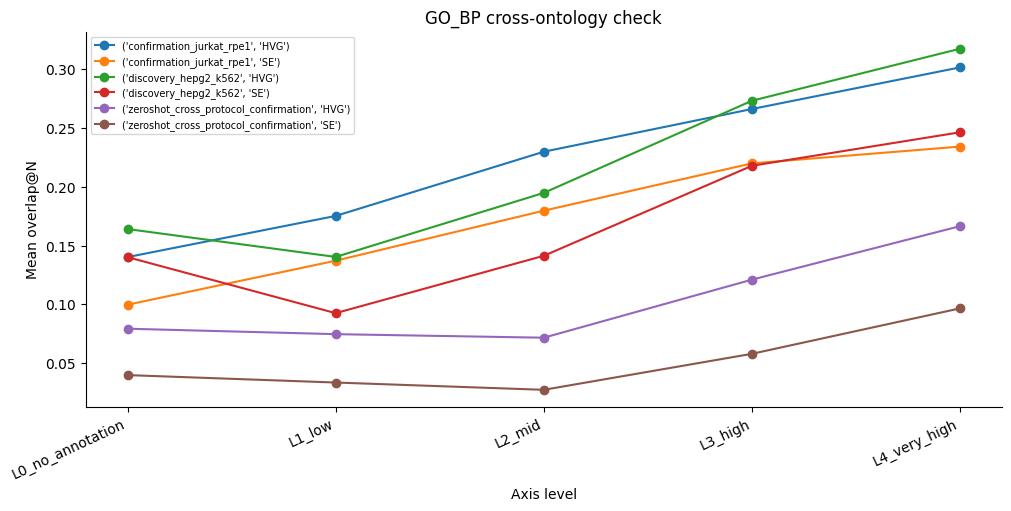

,spectra_subset,representation,level,level_order,n_rows,n_unique_contexts,n_unique_perturbations,similarity_mean,feature_count_mean,overlap_at_N_mean,de_sig_genes_recall_mean,pearson_delta_mean
0,confirmation_jurkat_rpe1,HVG,L0_no_annotation,0,64,2,44,0.000000,0.000000,0.140153,0.182412,0.309620
1,confirmation_jurkat_rpe1,HVG,L1_low,1,628,2,473,0.077991,8.614650,0.175189,0.207943,0.344792
2,confirmation_jurkat_rpe1,HVG,L2_mid,2,571,2,458,0.175448,9.047285,0.229826,0.264836,0.444693
3,confirmation_jurkat_rpe1,HVG,L3_high,3,480,2,401,0.262077,5.985417,0.266164,0.295177,0.485360
4,confirmation_jurkat_rpe1,HVG,L4_very_high,4,402,2,317,0.432898,3.661692,0.301576,0.336504,0.518098
5,confirmation_jurkat_rpe1,SE,L0_no_annotation,0,64,2,44,0.000000,0.000000,0.099637,0.132816,0.269980
6,confirmation_jurkat_rpe1,SE,L1_low,1,628,2,473,0.077991,8.614650,0.137076,0.167364,0.300512
7,confirmation_jurkat_rpe1,SE,L2_mid,2,571,2,458,0.175448,9.047285,0.179665,0.211201,0.383565
8,confirmation_jurkat_rpe1,SE,L3_high,3,480,2,401,0.262077,5.985417,0.219906,0.259654,0.428735
9,confirmation_jurkat_rpe1,SE,L4_very_high,4,402,2,317,0.432898,3.661692,0.234186,0.277991,0.465390


,spectra_subset,representation,n_levels,n_rows,similarity_monotone_increasing,spearman_level_vs_overlap_at_N,low_level,high_level,low_overlap_at_N_mean,high_overlap_at_N_mean,high_minus_low_overlap_at_N
0,confirmation_jurkat_rpe1,HVG,5,2145,True,1.0,L0_no_annotation,L4_very_high,0.140153,0.301576,0.161422
1,confirmation_jurkat_rpe1,SE,5,2145,True,1.0,L0_no_annotation,L4_very_high,0.099637,0.234186,0.134550
2,discovery_hepg2_k562,HVG,5,1913,True,0.9,L0_no_annotation,L4_very_high,0.164019,0.317470,0.153451
3,discovery_hepg2_k562,SE,5,1913,True,0.9,L0_no_annotation,L4_very_high,0.140117,0.246361,0.106244
4,zeroshot_cross_protocol_confirmation,HVG,5,5759,True,0.6,L0_no_annotation,L4_very_high,0.079207,0.166491,0.087284
5,zeroshot_cross_protocol_confirmation,SE,5,5759,True,0.6,L0_no_annotation,L4_very_high,0.039733,0.096526,0.056794


In [9]:
m_LEVEL_ORDER={'L0_no_annotation':0,'L1_low':1,'L2_mid':2,'L3_high':3,'L4_very_high':4}
m_TARGET_METRIC='overlap_at_N'
def m_safe_mean(x: pd.Series) -> float:
    vals = pd.to_numeric(x, errors='coerce').dropna()
    return float(vals.mean()) if len(vals) else float('nan')

def m_summarize(examples: pd.DataFrame, level_col: str) -> tuple[pd.DataFrame, pd.DataFrame]:
    rows = []
    for (subset, rep, level), sub in examples.groupby(['spectra_subset', 'representation', level_col]):
        rows.append({'spectra_subset': subset, 'representation': rep, 'level': level, 'level_order': m_LEVEL_ORDER.get(str(level), -1), 'n_rows': int(len(sub)), 'n_unique_contexts': int(sub['context'].nunique()), 'n_unique_perturbations': int(sub['gene_symbol_canonical'].nunique()), 'similarity_mean': m_safe_mean(sub['support_norm_log_mean']), 'feature_count_mean': m_safe_mean(sub['feature_count']), 'overlap_at_N_mean': m_safe_mean(sub['overlap_at_N']), 'de_sig_genes_recall_mean': m_safe_mean(sub['de_sig_genes_recall']), 'pearson_delta_mean': m_safe_mean(sub['pearson_delta'])})
    levels = pd.DataFrame(rows).sort_values(['spectra_subset', 'representation', 'level_order'])
    trend_rows = []
    for (subset, rep), sub in levels.groupby(['spectra_subset', 'representation']):
        valid = sub[sub['level_order'] >= 0].sort_values('level_order')
        if len(valid) < 2:
            continue
        low = valid.iloc[0]
        high = valid.iloc[-1]
        trend_rows.append({'spectra_subset': subset, 'representation': rep, 'n_levels': int(len(valid)), 'n_rows': int(valid['n_rows'].sum()), 'similarity_monotone_increasing': bool(valid['similarity_mean'].is_monotonic_increasing), 'spearman_level_vs_overlap_at_N': float(valid['level_order'].corr(valid['overlap_at_N_mean'], method='spearman')), 'low_level': low['level'], 'high_level': high['level'], 'low_overlap_at_N_mean': float(low['overlap_at_N_mean']), 'high_overlap_at_N_mean': float(high['overlap_at_N_mean']), 'high_minus_low_overlap_at_N': float(high['overlap_at_N_mean'] - low['overlap_at_N_mean'])})
    return (levels, pd.DataFrame(trend_rows))

def m_ols_support_coef(examples: pd.DataFrame) -> dict[str, float]:
    work = examples[examples['feature_count'] > 0].dropna(subset=['support_norm_log_mean', m_TARGET_METRIC]).copy()
    if len(work) < 50:
        return {'n_rows': int(len(work)), 'coef': float('nan'), 't': float('nan'), 'r2': float('nan')}
    y = pd.to_numeric(work[m_TARGET_METRIC], errors='coerce').to_numpy(float)
    cols = []
    names = []

    def add(name: str, vals: np.ndarray, standardize: bool=True) -> None:
        vals = vals.astype(float)
        if standardize:
            sd = float(np.std(vals))
            vals = (vals - float(np.mean(vals))) / sd if sd > 0 else vals * 0
        cols.append(vals)
        names.append(name)
    add('support_norm_log_mean_z', pd.to_numeric(work['support_norm_log_mean'], errors='coerce').to_numpy(float))
    add('feature_count_z', pd.to_numeric(work['feature_count'], errors='coerce').to_numpy(float))
    add('log1p_de_nsig_counts_real_z', np.log1p(pd.to_numeric(work['de_nsig_counts_real'], errors='coerce').fillna(0).to_numpy(float)))
    for col in ['context', 'representation', 'spectra_subset']:
        dummies = pd.get_dummies(work[col], prefix=col, drop_first=True, dtype=float)
        for dcol in dummies.columns:
            cols.append(dummies[dcol].to_numpy(float))
            names.append(dcol)
    x = np.column_stack([np.ones(len(work)), *cols])
    beta, *_ = np.linalg.lstsq(x, y, rcond=None)
    yhat = x @ beta
    ss_res = float(np.sum((y - yhat) ** 2))
    ss_tot = float(np.sum((y - np.mean(y)) ** 2))
    sigma2 = ss_res / max(len(work) - x.shape[1], 1)
    cov = sigma2 * np.linalg.pinv(x.T @ x)
    se = np.sqrt(np.diag(cov))
    idx = names.index('support_norm_log_mean_z') + 1
    return {'n_rows': int(len(work)), 'coef': float(beta[idx]), 'se': float(se[idx]), 't': float(beta[idx] / se[idx]) if se[idx] else float('nan'), 'r2': 1 - ss_res / ss_tot if ss_tot else float('nan')}

curve,trends=m_summarize(examples,LEVEL)
controlled=m_ols_support_coef(few)
display(pd.DataFrame([controlled]))

def plot_curve(table,title):
    figure,axis=plt.subplots(figsize=(10,5),layout='constrained')
    group_cols=[x for x in ['spectra_subset','representation'] if x in table]
    order=sorted(table.level.astype(str).unique())
    xmap={value:i for i,value in enumerate(order)}
    groups=table.groupby(group_cols,dropna=False) if group_cols else [('STATE',table)]
    for name,part in groups:
        part=part.copy();part['x']=part.level.astype(str).map(xmap);part=part.sort_values('x')
        axis.plot(part.x,part.overlap_at_N_mean,marker='o',label=str(name))
    axis.set_xticks(range(len(order)),order,rotation=25,ha='right')
    axis.set(xlabel='Axis level',ylabel='Mean overlap@N',title=title)
    axis.legend(fontsize=7);axis.spines[['top','right']].set_visible(False)
    figure.savefig(OUTPUTS/'curve.png',dpi=150)
    plt.show()
plot_curve(curve,TITLE)
display(curve)
display(trends)


## 6. What the agent decided, and why

The decision below follows the calculated curve and relevant controls. A positive high-minus-low support contrast means better prediction where training-reference support is higher.


In [10]:
confirmation=trends[trends.spectra_subset.isin(['confirmation_jurkat_rpe1','zeroshot_cross_protocol_confirmation'])]
supported=len(confirmation)==4 and (confirmation.high_minus_low_overlap_at_N>0).all() and confirmation.similarity_monotone_increasing.all() and (confirmation.n_levels>=3).all()
decision='Accept '+COLLECTION+' as supporting the training-support association' if supported else 'Reject '+COLLECTION+' as a consistent training-support association'
print(decision)
display(confirmation[['spectra_subset','representation','high_minus_low_overlap_at_N']])
print('Adjusted few-shot support coefficient:',controlled['coef'])


Accept GO_BP as supporting the training-support association


,spectra_subset,representation,high_minus_low_overlap_at_N
0,confirmation_jurkat_rpe1,HVG,0.161422
1,confirmation_jurkat_rpe1,SE,0.134550
4,zeroshot_cross_protocol_confirmation,HVG,0.087284
5,zeroshot_cross_protocol_confirmation,SE,0.056794


Adjusted few-shot support coefficient: 0.014513540797310036


In [11]:
examples.to_csv(OUTPUTS/'per_condition_results.csv',index=False)
curve.to_csv(OUTPUTS/'curve.csv',index=False)
trends.to_csv(OUTPUTS/'trends.csv',index=False)
receipt={'analysis_id':ANALYSIS_ID,'completed':True,'host':os.uname().nodename,
         'elapsed_seconds':round(time.time()-STARTED,3),'decision':decision,
         'custom_external_code_used':False,'model_inference_performed':False,
         'audit_specific_fine_tuning':False,'source_files':source_receipts,
         'rows':len(examples),'output_files':{name:sha256_file(OUTPUTS/name) for name in
             ['per_condition_results.csv','curve.csv','trends.csv','curve.png']}}
(OUTPUTS/'execution_record.json').write_text(json.dumps(receipt,indent=2,default=str)+'\n')
print('Completed:',ANALYSIS_ID,'on',receipt['host'])


Completed: state-featured/test-15 on exxact05.broadinstitute.org
